# Remnant energetics of the GWTC population

**Question.** How much rotational energy survives a binary black-hole merger, and
what thin-disc radiative efficiency does the inferred remnant spin imply?

**Method.** Component masses and the effective inspiral spin `chi_eff` come from the
GWTC catalogue. The remnant spin is estimated with the aligned-spin fit of
Rezzolla et al. (2008), assuming `chi_1 = chi_2 = chi_eff`. The exact prograde Kerr
ISCO (Bardeen-Press-Teukolsky 1972) then gives the specific orbital energy
`E_ISCO`, and `eta = 1 - E_ISCO`. The irreducible mass gives the rotational
reservoir `E_rot = (M - M_irr) c^2`.

**Caveat.** The spin is a point estimate, not a posterior sample, and the aligned-spin
assumption is approximate. Conclusions are population-level, not per-event
measurements.

In [1]:
from pathlib import Path
import subprocess, sys
import pandas as pd

# Locate the project root whether the notebook runs from the project or notebooks/.
root = Path.cwd()
while root != root.parent and not (root / "scripts" / "remnant_energetics.py").exists():
    root = root.parent
assert (root / "scripts" / "remnant_energetics.py").exists(), root

csv = root / "results" / "remnant_energetics.csv"
if not csv.exists():
    subprocess.run([sys.executable, str(root / "scripts" / "remnant_energetics.py")], check=True, cwd=root)

df = pd.read_csv(csv)
print(f"{len(df)} remnants with complete masses and effective spin")
df.head(8)[["event_id", "final_mass_source", "chi_eff", "a_fit", "eta_radiative", "e_rot_msun"]]

270 remnants with complete masses and effective spin


,event_id,final_mass_source,chi_eff,a_fit,eta_radiative,e_rot_msun
0,GW250119_190238,20.56,0.09,0.728711,0.108097,1.689429
1,GW250119_025138,57.10,0.06,0.709322,0.105006,4.380820
2,GW250118_170523,64.40,0.12,0.738759,0.109801,5.482448
3,GW250118_055802,16.60,0.11,0.722078,0.107011,1.332461
4,GW250118_023225,71.00,0.04,0.690534,0.102233,5.094185
5,GW250116_015318,53.00,0.15,0.735660,0.109267,4.463003
6,GW250114_082203,62.90,-0.03,0.671173,0.099577,4.208856
7,GW250109_074552,65.90,0.07,0.713155,0.105597,5.125213


## Population summary

The Kerr bound is `1 - 1/sqrt(3) = 0.4226` and is approached only as `a -> 1`.
A Schwarzschild ISCO (6 GM/c^2) is the zero-spin baseline.

In [2]:
summary = {
    "events": len(df),
    "median a*": round(df.a_fit.median(), 3),
    "90th pct a*": round(df.a_fit.quantile(0.9), 3),
    "max a*": round(df.a_fit.max(), 3),
    "median eta": round(df.eta_radiative.median(), 4),
    "eta range (10-90%)": (round(df.eta_radiative.quantile(0.1), 4), round(df.eta_radiative.quantile(0.9), 4)),
    "Kerr bound": round(1 - 1/3**0.5, 4),
    "Schwarzschild eta": round(1 - (6**1.5 - 2*6**0.5) / (6**0.75 * (6**1.5 - 3*6**0.5)**0.5), 4),
    "mean ISCO overshoot": round(df.isco_ratio_schw_over_kerr.mean(), 2),
    "max ISCO overshoot": round(df.isco_ratio_schw_over_kerr.max(), 2),
    "total E_rot [Msun c^2]": round(df.e_rot_msun.sum(), 0),
}
pd.Series(summary)

events                                 270
median a*                             0.69
90th pct a*                          0.774
max a*                                0.93
median eta                          0.1022
eta range (10-90%)        (0.0924, 0.1164)
Kerr bound                          0.4226
Schwarzschild eta                   0.0572
mean ISCO overshoot                   1.76
max ISCO overshoot                    2.85
total E_rot [Msun c^2]              1140.0
dtype: object

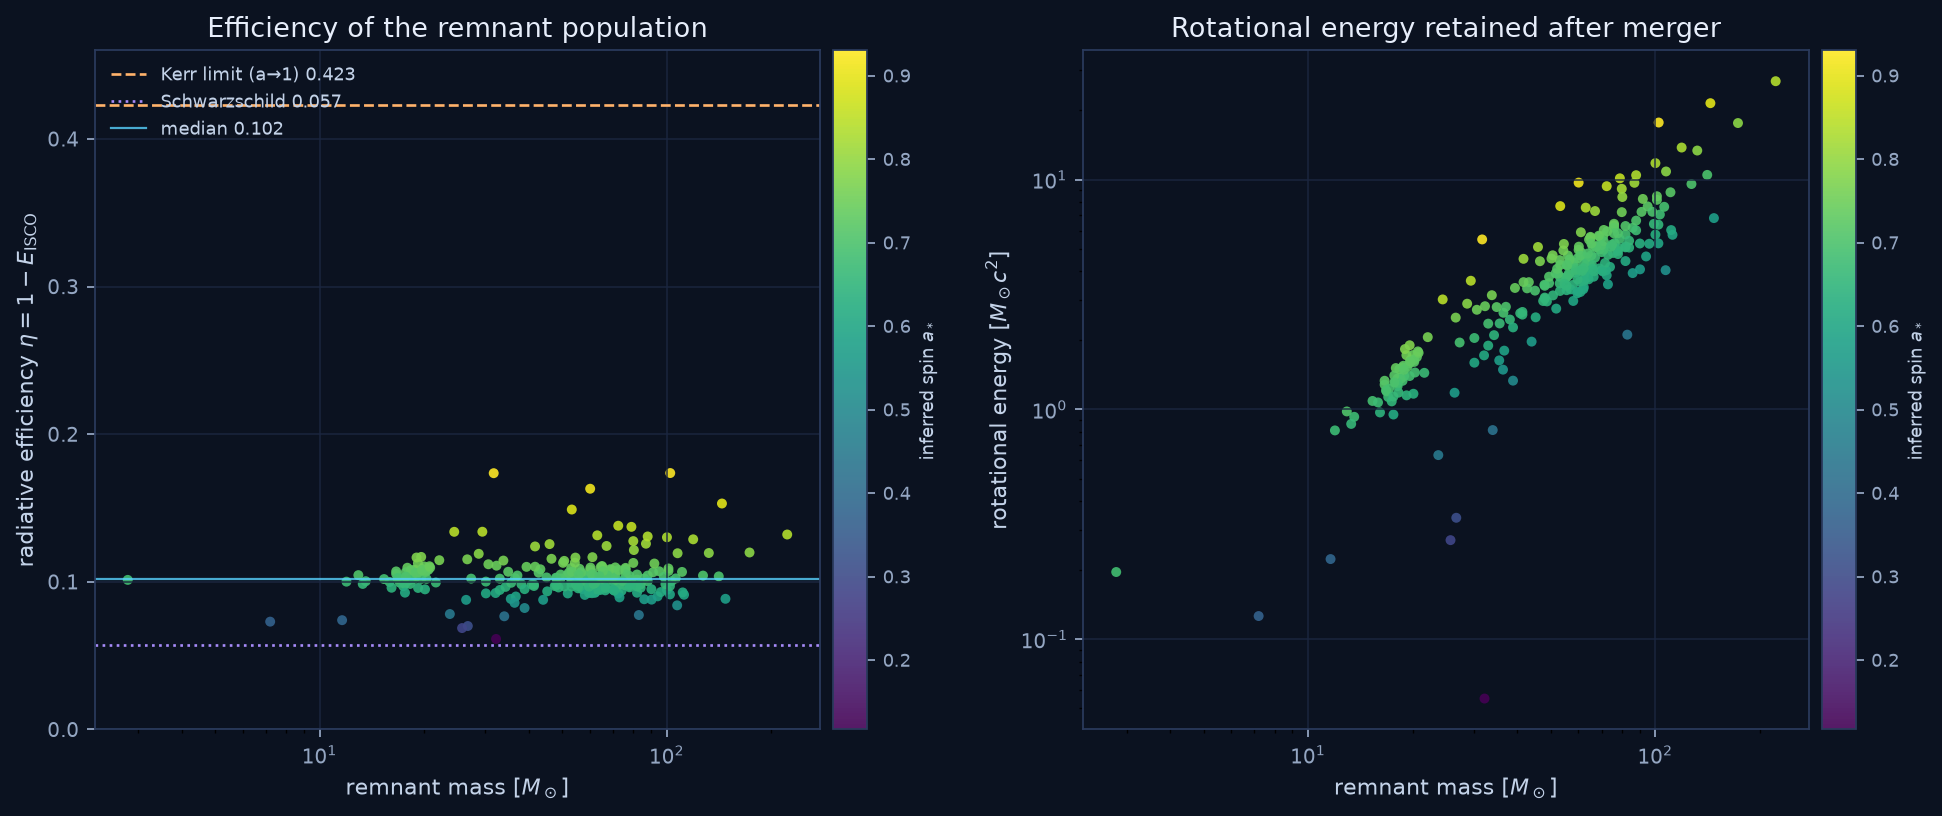

In [3]:
from IPython.display import Image, display
png = root / "results" / "remnant_energetics.png"
if png.exists():
    display(Image(filename=str(png)))
else:
    print("Run scripts/remnant_energetics.py to generate the figure.")

## Reading the result

1. The population is **modestly spinning**: the median efficiency is about 0.10,
   roughly twice the Schwarzschild value but far below the Kerr bound.
2. A **Schwarzschild ISCO is not a safe default** across the catalogue: it
   overestimates the radius by 1.76x on average and by more than 3x for the
   fastest remnants.
3. The **rotational reservoir is large** compared with the GW output, so
   spin-down channels have energy available; the efficiency bound still requires
   a horizonless object to be exceeded.
4. No event in this sample **requires** physics beyond a Kerr horizon under the
   adopted spin fit. That is a null result, not evidence for Kerr.

The full write-up is in `reports/remnant_energetics.md`.